# One image from a double-source-plane lens

One foreground mass at z=0.4 lenses a luminous galaxy at z=0.9. The
background galaxy at z=2.0 is lensed by both mass planes. Their light is
added into **one observed image**. Each galaxy has eight Sersic components.
There is one 122-element physical parameter vector, without a batch dimension.

Both implementations evaluate the same analytic SIE deflections, full coupled
Caustics multiplane ray trace and 5 x 5 Gaussian quadrature. No deflection map
interpolation or independent-simulator batch is used. This example renders
intrinsic surface brightness without a PSF.

Use this checkout's `.venv` as the notebook kernel. Two physical CUDA GPUs
are required. Preparation is excluded from forward timings.

In [1]:
import random
import statistics
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from IPython.display import SVG, display

project = Path.cwd()
while not (project / "pyproject.toml").exists() and project != project.parent:
    project = project.parent
sys.path.insert(0, str(project))
import niagara as ng  # noqa: E402
from examples.niagara_examples.multiplane_image import MultiplaneImage, ParallelMultiplaneImage  # noqa: E402

if torch.cuda.device_count() < 2:
    raise RuntimeError("This notebook requires two physical CUDA GPUs")
assert torch.cuda.get_device_properties(0).uuid != torch.cuda.get_device_properties(1).uuid
print(torch.__version__)
print([torch.cuda.get_device_name(i) for i in (0, 1)])

options = dict(size=1024, components=8, quad_level=5)
native = MultiplaneImage(**options, device="cuda:1")
params = native.get_values().detach().clone()
assert params.ndim == 1
print("One parameter vector:", tuple(params.shape))

2.12.0+cu126
['NVIDIA GeForce RTX 3090', 'NVIDIA GeForce RTX 3090']


One parameter vector: (122,)


## Submit the two physical light branches

Separate Caskade instances keep mutable activation state local to each worker.
Both copies receive the same physical parameter vector. The intermediate-light
image is copied to the background worker and added there. That communication
and addition are included in every forward call.

In [2]:
middle = MultiplaneImage(**options, device="cuda:0")
background = MultiplaneImage(**options, device="cuda:1")
eager = ParallelMultiplaneImage(middle, background, params, compiled=False)

reference = native(params).detach()
image = eager(params)
assert image.shape == (options["size"], options["size"])
torch.testing.assert_close(image, reference, rtol=3e-4, atol=3e-4)
print("One output image:", tuple(image.shape), image.device)
print("Maximum eager image difference:", (image - reference).abs().max().item())

One output image: (1024, 1024) cuda:1
Maximum eager image difference: 0.0


## Compile the same work

Compile pure light branches before submitting them to workers. The native
single-GPU control directly compiles the original Caskade scene. All methods
use the same precision, components and pixel integration.

In [3]:
compiled = ParallelMultiplaneImage(middle, background, params, compiled=True)
direct = torch.compile(native, fullgraph=False, options={"triton.cudagraphs": False})

direction = torch.linspace(-1, 1, params.numel(), device=params.device) * params.abs().clamp_min(0.01)
points = (params, params + 0.005 * direction, params - 0.003 * direction)
for point in points:
    expected = native(point)
    torch.testing.assert_close(compiled(point), expected, rtol=3e-4, atol=3e-4)
    torch.testing.assert_close(direct(point), expected, rtol=3e-4, atol=3e-4)
assert not torch.equal(compiled(points[0]), compiled(points[1]))
print("Changing-input checks passed")
print("Compiled branch backends:", [program.backend for program in compiled.functions])

Changing-input checks passed
Compiled branch backends: ['cuda_graph', 'cuda_graph']


## Measure completed forward calls

Each timed block evaluates three individual changing parameter vectors. Both
devices are synchronized at the block boundaries. This includes copies and
the final image sum; it is not a measurement of CUDA submission time.
The reusable benchmark additionally compares Niagara compilation on one GPU
and validates gradients over every pixel and all 122 scalar parameters.

In [4]:
def synchronize():
    for index in (0, 1):
        torch.cuda.synchronize(index)

functions = {
    "Native eager, one GPU": native,
    "Niagara eager, two GPUs": eager,
    "Direct torch.compile, one GPU": direct,
    "Niagara compiled, two GPUs": compiled,
}
for function in functions.values():
    for point in points * 2:
        function(point)
synchronize()

samples = {name: [] for name in functions}
generator = random.Random(181)
for _repeat in range(10):
    order = list(functions)
    generator.shuffle(order)
    for name in order:
        synchronize()
        start = time.perf_counter()
        for point in points:
            functions[name](point)
        synchronize()
        samples[name].append(1000 * (time.perf_counter() - start) / len(points))

for name, values in samples.items():
    print(f"{name:35s} {statistics.median(values):9.3f} ms/image")

Native eager, one GPU                 190.428 ms/image
Niagara eager, two GPUs               138.205 ms/image
Direct torch.compile, one GPU          18.860 ms/image
Niagara compiled, two GPUs              5.220 ms/image


## View the single image and measured overlap

The timeline contains recorded device activity. CUDA kernels may fuse several
operations, and profiling adds overhead; use the timings above for performance.
Use `rankdir="TB"` to put time on the vertical axis.

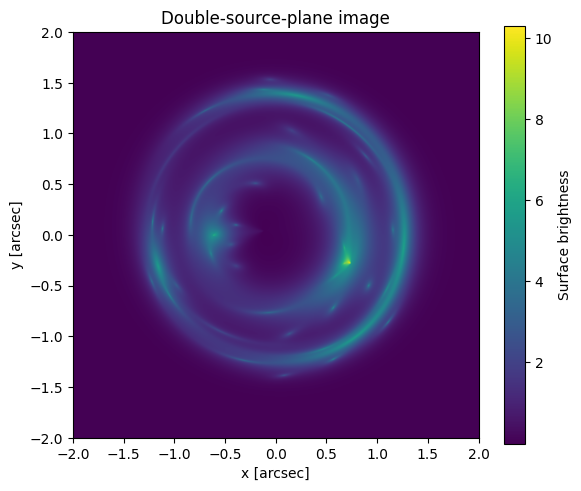

G:\Qsync\Maitrise\Projects\Niagara\.venv\Lib\site-packages\torch\profiler\profiler.py:272: UserWarning: Warning: Profiler clears events at the end of each cycle.Only events from the current cycle will be reported.To keep events across cycles, set acc_events=True.
  _warn_once(


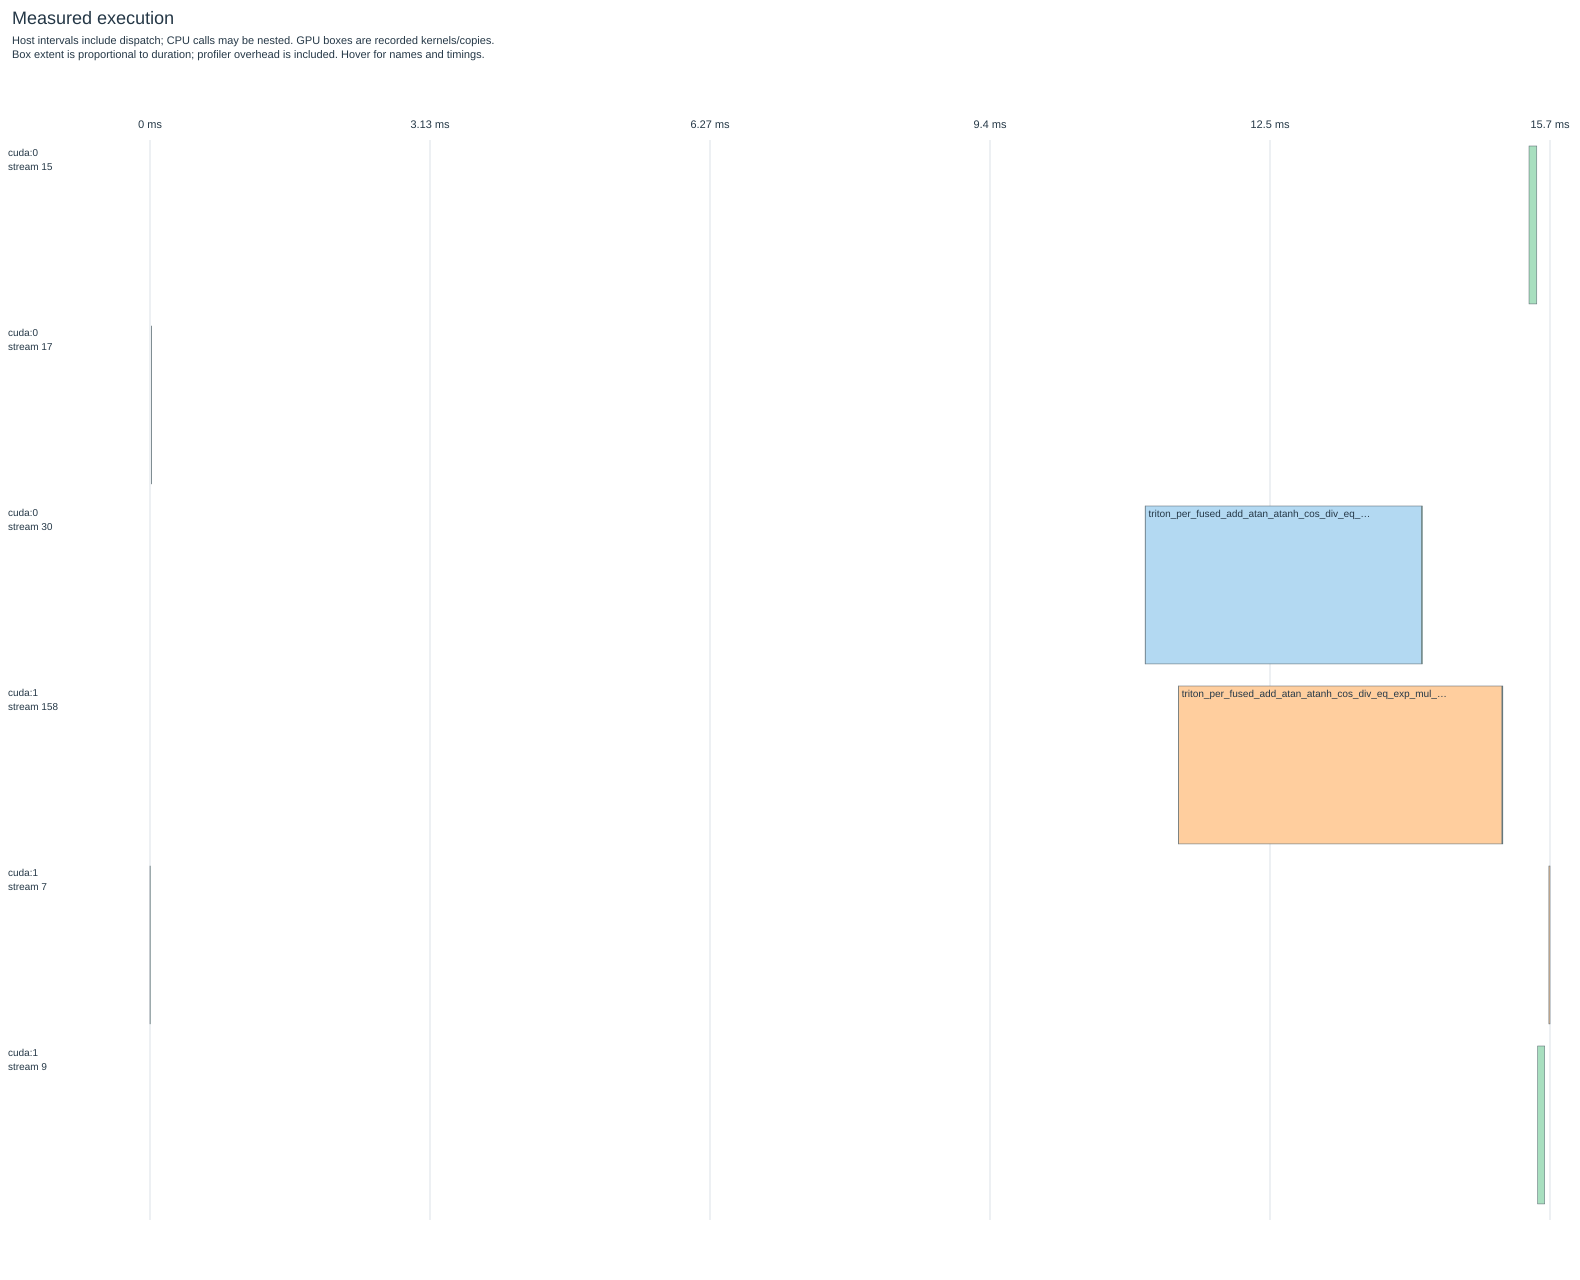

In [5]:
image = compiled(points[1]).detach().cpu()
plt.figure(figsize=(6, 5))
plt.imshow(image, origin="lower", extent=(-2, 2, -2, 2))
plt.title("Double-source-plane image")
plt.xlabel("x [arcsec]")
plt.ylabel("y [arcsec]")
plt.colorbar(label="Surface brightness")
plt.tight_layout()
plt.show()

out = project / "results/multiplane_image_notebook"
out.mkdir(parents=True, exist_ok=True)
trace = out / "trace.json"
_ = ng.profile(compiled, (points[1],), trace, iterations=1, warmup=3)
timeline = ng.draw_timeline(trace, rankdir="LR", time_size=1400, devices=("cuda:0", "cuda:1"))
display(SVG(data=timeline.pipe(format="svg").decode("utf-8")))

## Placement graphs and compiled graphs

Each worker owns a separate copy of the scene's state and executes one selected
light branch. The placement graphs show that state ownership. Unused modules
in a copy do not execute; the compiled graph shows the operations of the
selected branch. Both branches produce the same single observed image after
their light contributions are added.

Set `graph_direction` to `"TB"` or `"LR"`. Placement views use temporary drawing
copies, so the already compiled workers and their guards are left intact.

Middle worker placement: cuda:0


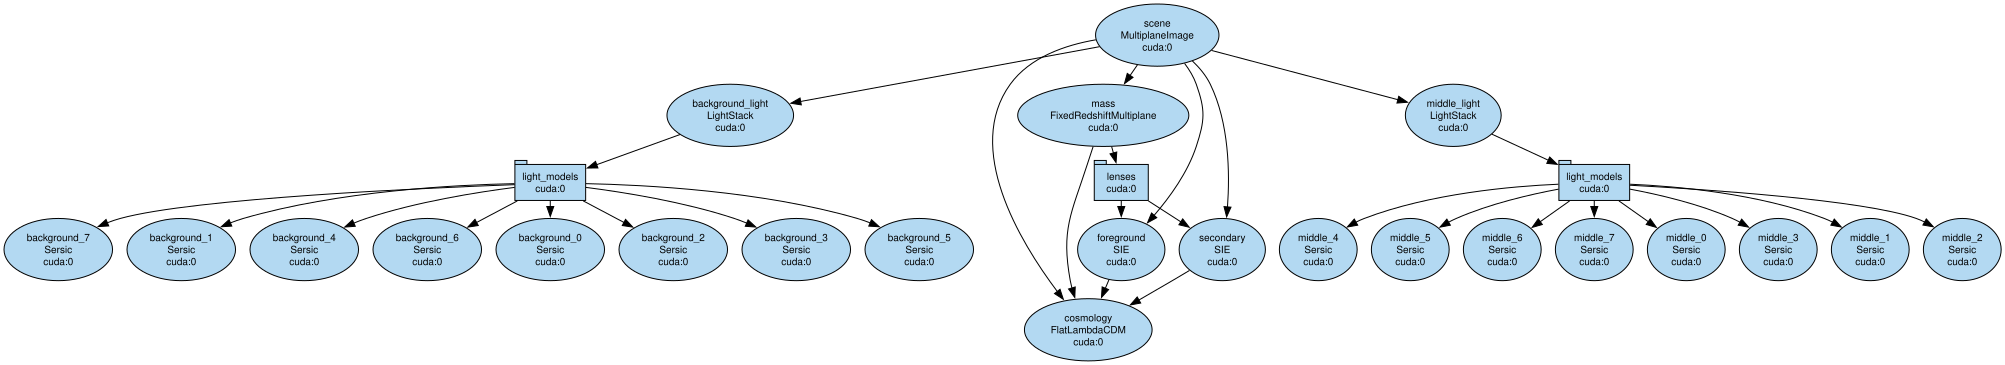

Background worker placement: cuda:1


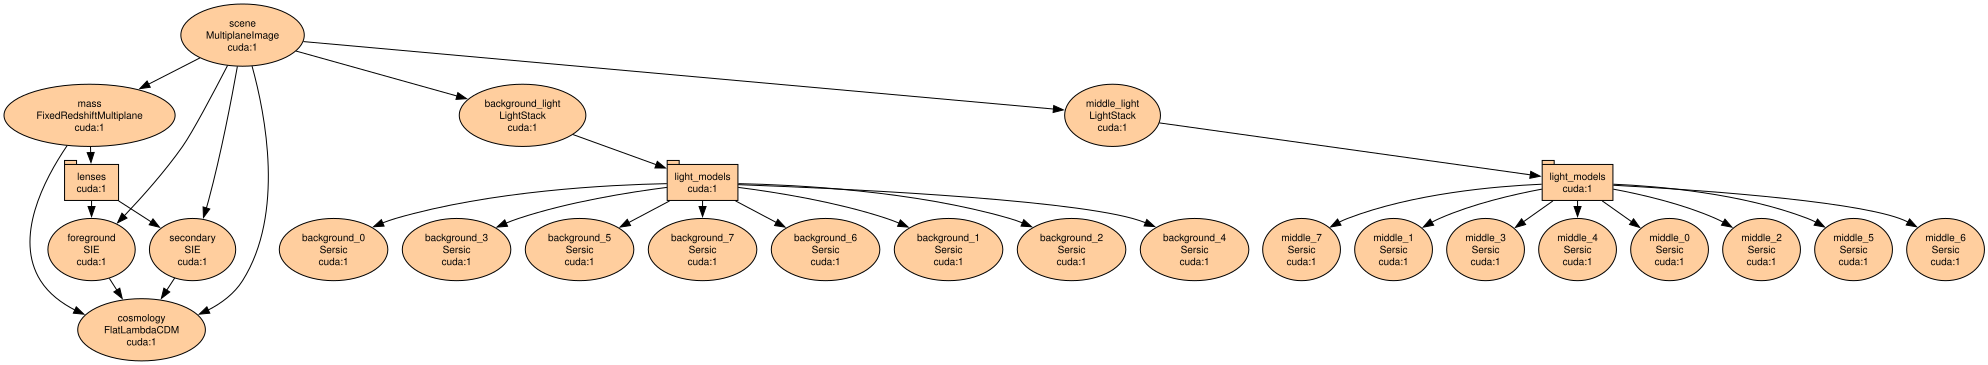

In [6]:
graph_direction = "TB"
graph_dir = project / "results/multiplane_image_20261029/placement_compiled"
graph_dir.mkdir(parents=True, exist_ok=True)

for branch, home in (("middle", "cuda:0"), ("background", "cuda:1")):
    diagram_model = MultiplaneImage(**options, device=home)
    with ng.assign_devices(diagram_model, ng.DevicePlan(default=home)) as placement:
        graph = ng.draw_model(
            diagram_model, placement=placement, parameters=False,
            devices=True, rankdir=graph_direction,
        )
        graph.attr(ranksep="0.25", nodesep="0.2")
        svg = graph.pipe(format="svg").decode("utf-8")
        (graph_dir / f"{branch}_placement_{graph_direction}.svg").write_text(svg, encoding="utf-8")
        print(f"{branch.capitalize()} worker placement: {home}")
        display(SVG(data=svg))
del diagram_model


Middle compiled graph; backend = cuda_graph


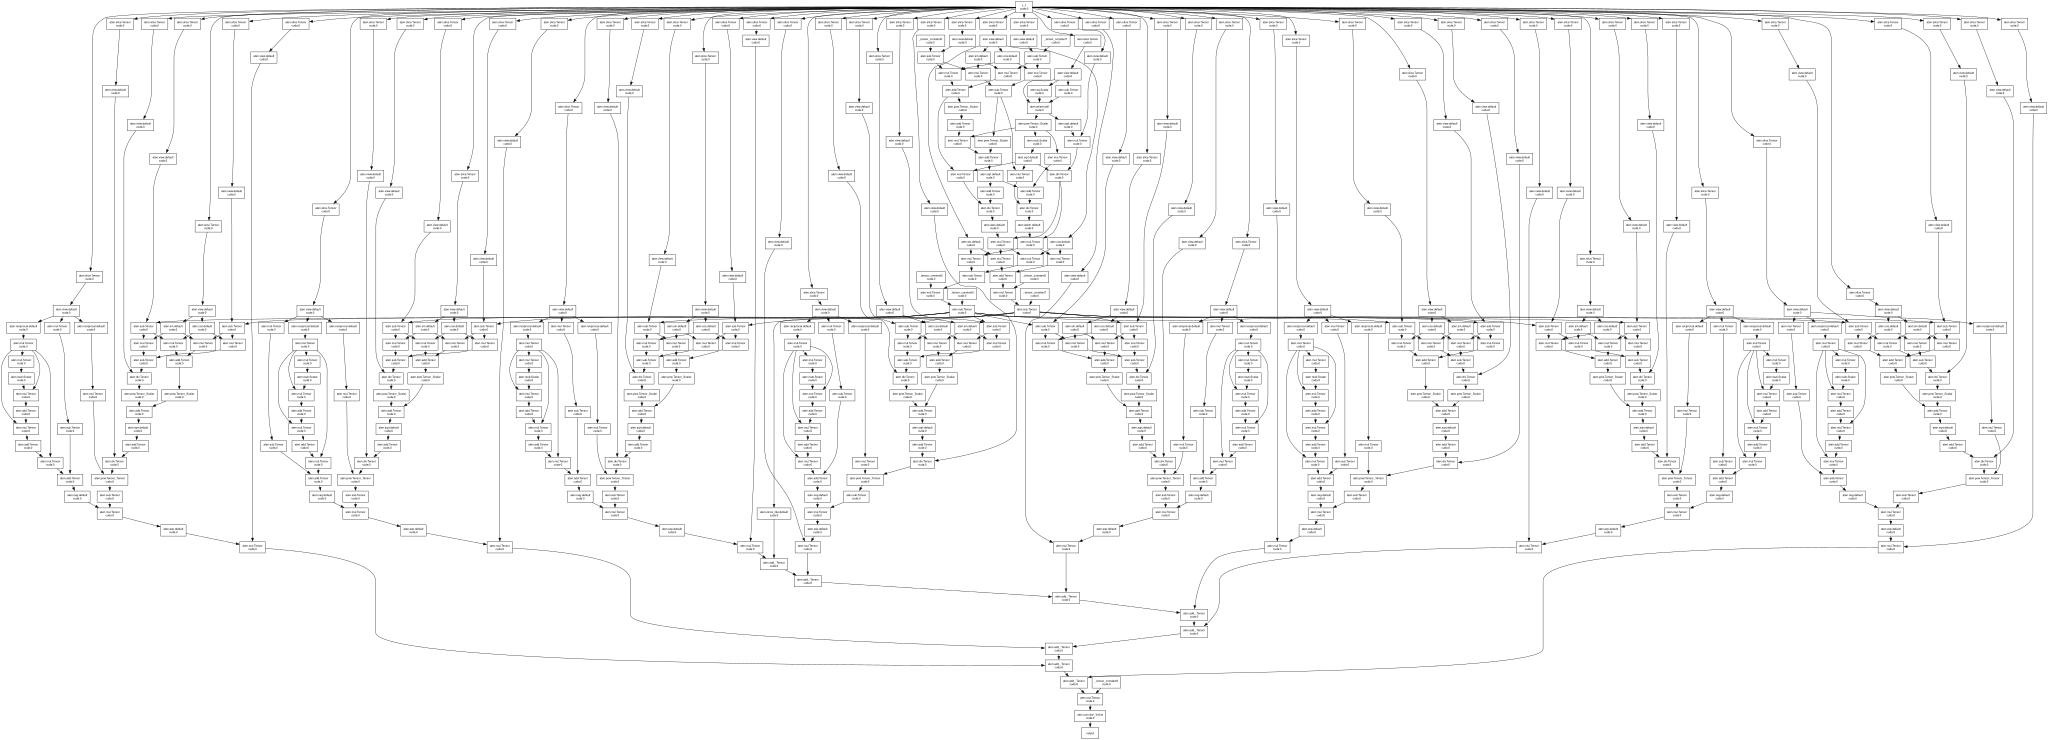

Background compiled graph; backend = cuda_graph


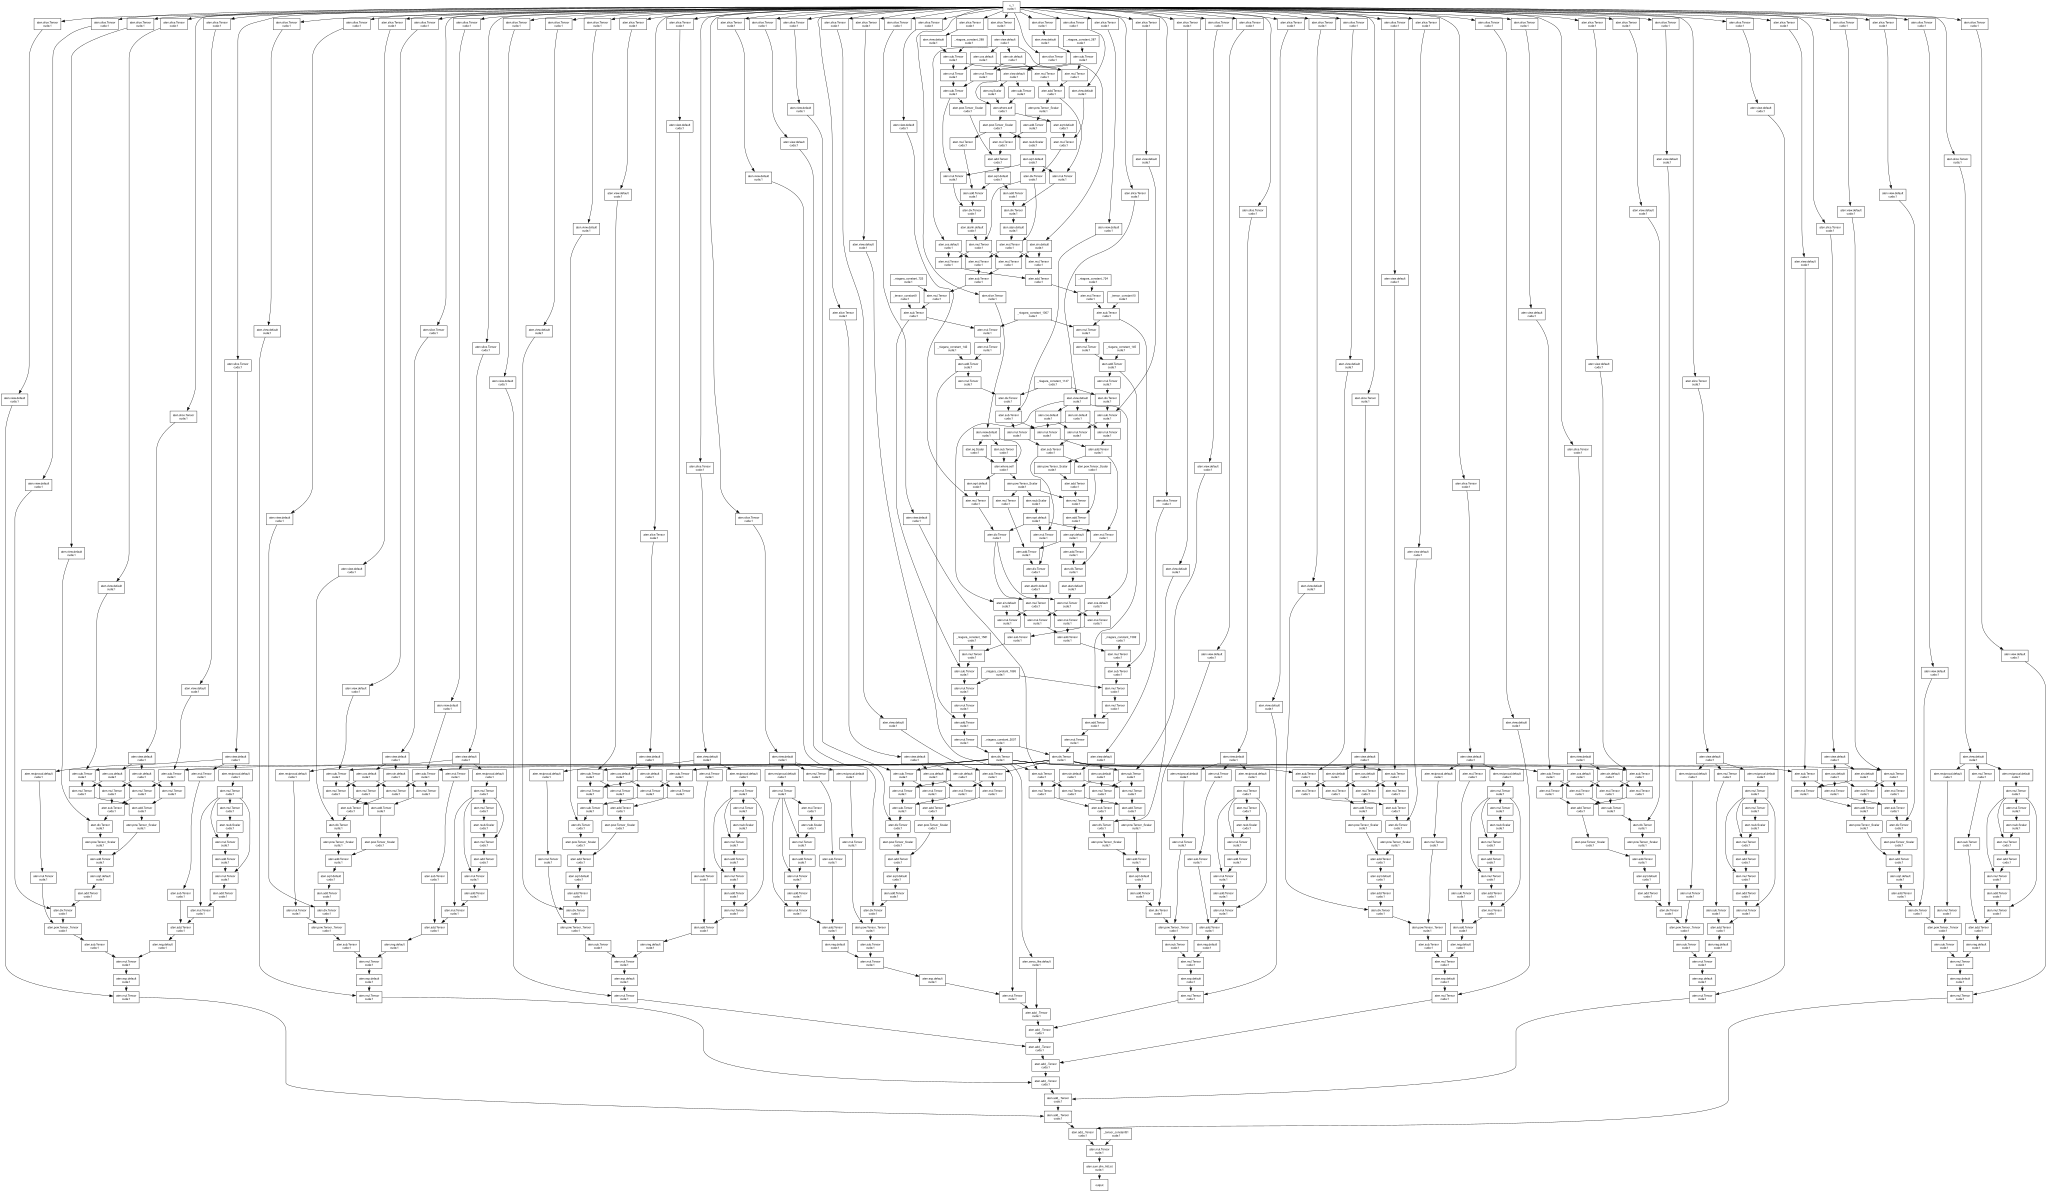

In [7]:
for branch, program in zip(("middle", "background"), compiled.functions):
    graph = ng.draw_execution(
        program, scopes=False, devices=True, shapes=False,
        rankdir=graph_direction,
    )
    graph.attr(ranksep="0.25", nodesep="0.2")
    svg = graph.pipe(format="svg").decode("utf-8")
    (graph_dir / f"{branch}_compiled_{graph_direction}.svg").write_text(svg, encoding="utf-8")
    print(f"{branch.capitalize()} compiled graph; backend = {program.backend}")
    display(SVG(data=svg))


In [8]:
eager.close()
compiled.close()
print("Device workers closed")

Device workers closed


## Full reproducible validation

Run from the checkout with its `.venv`:

```console
python benchmarks/multiplane_image.py --size 1024 --components 8 --quad 5 --repeats 20 --trace --out results/multiplane_image
```

The benchmark retains dependency versions, source hashes and source snapshots,
changed-input checks, full-resolution image and gradient errors, individual
timing samples, preparation costs and actual GPU traces. Spatial chunks are
used only to limit reference-autograd memory during validation. Every timed
forward call renders the complete single image without simulator batching.
No posterior-fit or data-accuracy claim is made by this synthetic example.